# Project: Data Wrangling and Analysis (FDA AI Medical Devices)

## Table of contents

<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#gather">Gather</a></li>
<li><a href="#access">Access</a></li>
<li><a href="#clean">Clean</a></li>
<li><a href="#eda">Analysing and Visualization of data</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id="intro"></a>
## Introduction

The integration of Artificial Intelligence and Machine Learning (AI/ML) in medical devices is rapidly transforming healthcare. This project explores datasets containing FDA authorizations, product classifications, and recall events for AI-enabled medical devices. The goal is to wrangle the data, assess its quality, clean it for analysis, and perform detailed exploratory data analysis (EDA) to understand market growth, dominant medical specialties, review timelines, and the post-market risk profile of these devices.

**Dataset:** [FDA AI Medical Devices Authorizations and Recalls](https://www.kaggle.com/datasets/kylefengkfeng209/fda-ai-medical-devices-authorizations-and-recalls)


<a id="gather"></a>

# Gather

In [1]:
# Import required libraries:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import os
%matplotlib inline

# Configure visual aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = 11, 7

#### FDA AI Medical Devices, Product Codes, and Recalls Datasets

In [2]:
# Read the .csv files into dataframes
devices_df = pd.read_csv("fda_ai_medical_devices.csv")
codes_df = pd.read_csv("fda_ai_product_codes.csv")
recalls_df = pd.read_csv("fda_ai_device_recalls.csv")

- The above code loaded the datasets containing the device authorizations, product code classifications, and linked recall records into their respective pandas dataframes.

<a id="access"></a>

# Access

### Visual assessment

In [3]:
# Taking a view of the devices_df table
devices_df.head(3)

,submission_number,authorization_pathway,final_decision_date,decision_year,decision_quarter,device_name,company_name,fda_panel,primary_product_code,authorization_detail_matched,...,linked_recall_events,open_recall_records,closed_recall_records,first_recall_initiated_date,latest_recall_initiated_date,days_to_first_recall,has_linked_recall,recall_linkage_method,source_snapshot_date,fda_ai_list_url
0,K254207,510(k),2026-03-30,2026,Q1,AiORTA - Plan v2.0,"ViTAA Medical Solutions, Inc.",Radiology,QIH,1,...,0,0,0,NaN,NaN,NaN,0,exact_submission_number_only,2026-07-31,https://www.fda.gov/medical-devices/software-m...
1,K252360,510(k),2026-03-28,2026,Q1,ECG-AI Pulmonary Hypertension (PH) 12-Lead alg...,"Anumana, Inc.",Cardiovascular,SAT,1,...,0,0,0,NaN,NaN,NaN,0,exact_submission_number_only,2026-07-31,https://www.fda.gov/medical-devices/software-m...
2,K252148,510(k),2026-03-27,2026,Q1,Butterfly Gestational Age Tool,"Butterfly Network, Inc.",Radiology,IYN,1,...,0,0,0,NaN,NaN,NaN,0,exact_submission_number_only,2026-07-31,https://www.fda.gov/medical-devices/software-m...


In [4]:
# Taking a view of the recalls_df table
recalls_df.head(3)

,recall_link_id,submission_number,authorization_pathway,device_name,company_name,final_decision_date,primary_product_code,cfres_id,res_event_number,product_res_number,...,product_description,code_info,product_quantity,reason_for_recall,root_cause_description,action,distribution_pattern,linked_submission_field,linkage_method,source_snapshot_date
0,K240465|220683,K240465,510(k),O-arm O2 Imaging System,"Medtronic Navigation, Inc",2024-06-21,OWB,220683,99041,Z-2451-2026,...,Medtronic O-arm O2 Imaging System. Model Numbe...,Model Number: BI70002000. GTIN (Serial Numbers...,589 units,Potential for image artifacts caused by an ano...,Under Investigation by firm,Medtronic notified consignees on about 05/19/2...,Worldwide distribution - US Nationwide and the...,k_numbers,exact_submission_number,2026-07-31
1,K252842|220295,K252842,510(k),SafeOp 3: Neural Informatix System,"Alphatec Spine, Inc.",2026-01-11,GWF,220295,98967,Z-2793-2026,...,"SafeOp Patient Interface, REF: AIX11240, part ...",UDI-DI: 00190376517506.\nSystem Set ID/Patient...,3,"Intraoperative neuromonitoring device, due to ...",Software Design Change,"On 5/13/2026, recall notices were emailed to c...",US Nationwide distribution in the states of TX...,k_numbers,exact_submission_number,2026-07-31
2,K250330|220230,K250330,510(k),3mensio Workstation,Pie Medical Imaging BV,2025-11-03,QIH,220230,98930,Z-2767-2026,...,3mensio Workstation (Vascular Fenestrated) sof...,Software Version 10.7.\nUDIs:\n(01)08056304455...,165,User measurement value reported by diagnostic ...,Software change control,"On 5/7/2026, correction notices were emailed t...",Worldwide - US Nationwide distribution in the ...,k_numbers,exact_submission_number,2026-07-31


### Programmatic assessment

In [5]:
# Taking a view of the devices_df summary
devices_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1524 entries, 0 to 1523
Data columns (total 44 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   submission_number                             1524 non-null   object 
 1   authorization_pathway                         1524 non-null   object 
 2   final_decision_date                           1524 non-null   object 
 3   decision_year                                 1524 non-null   int64  
 4   decision_quarter                              1524 non-null   object 
 5   device_name                                   1524 non-null   object 
 6   company_name                                  1524 non-null   object 
 7   fda_panel                                     1524 non-null   object 
 8   primary_product_code                          1524 non-null   object 
 9   authorization_detail_matched                  1524 non-null   i

In [6]:
# Taking a view of the recalls_df summary
recalls_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 313 entries, 0 to 312
Data columns (total 29 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   recall_link_id                     313 non-null    object
 1   submission_number                  313 non-null    object
 2   authorization_pathway              313 non-null    object
 3   device_name                        313 non-null    object
 4   company_name                       313 non-null    object
 5   final_decision_date                313 non-null    object
 6   primary_product_code               313 non-null    object
 7   cfres_id                           313 non-null    int64 
 8   res_event_number                   313 non-null    int64 
 9   product_res_number                 313 non-null    object
 10  recall_status                      313 non-null    object
 11  event_date_initiated               313 non-null    object
 12  event_da

In [7]:
# Checking for duplicated values across all dataframes
print("Devices duplicates:", devices_df.duplicated().sum())
print("Codes duplicates:", codes_df.duplicated().sum())
print("Recalls duplicates:", recalls_df.duplicated().sum())

Devices duplicates: 0
Codes duplicates: 0
Recalls duplicates: 0


## Quality

#### `devices_df` table
- `final_decision_date` and `date_received` are object datatypes, not datetime.
- `authorization_pathway` and `medical_specialty_description` are generic objects rather than categorical datatypes.

#### `recalls_df` table
- `event_date_initiated` and `final_decision_date` are object datatypes, not datetime.

### Tidiness
- The data is cleanly separated into relational tables, but for some visual analysis, merging device classifications with recall root causes may be beneficial later.

<a id="clean"></a>

# Clean

In [8]:
# create a copy for each dataset before cleaning
devices_clean = devices_df.copy()
codes_clean = codes_df.copy()
recalls_clean = recalls_df.copy()

### Date columns are object datatypes instead of datetime

#### Define

Change the `final_decision_date` and `date_received` in the `devices_clean` table, and `event_date_initiated` in the `recalls_clean` table to datetime objects so they can be effectively plotted and aggregated over time.

#### Code

In [9]:
# Convert string dates to datetime objects
devices_clean['final_decision_date'] = pd.to_datetime(devices_clean['final_decision_date'])
devices_clean['date_received'] = pd.to_datetime(devices_clean['date_received'])

recalls_clean['event_date_initiated'] = pd.to_datetime(recalls_clean['event_date_initiated'])
recalls_clean['final_decision_date'] = pd.to_datetime(recalls_clean['final_decision_date'])

#### Test

In [10]:
# Verify the datatype change
print(devices_clean['final_decision_date'].dtype)
print(recalls_clean['event_date_initiated'].dtype)

datetime64[ns]
datetime64[ns]


### Categorical variables stored as standard objects

#### Define

Convert structural columns like `authorization_pathway` and `medical_specialty_description` to the `category` datatype to optimize memory and standardise plotting.

#### Code

In [11]:
# Convert to category
devices_clean['authorization_pathway'] = devices_clean['authorization_pathway'].astype('category')
devices_clean['medical_specialty_description'] = devices_clean['medical_specialty_description'].astype('category')

#### Test

In [12]:
# Verify the datatype change
print(devices_clean['authorization_pathway'].dtype)

category


<a id="eda"></a>

## Analysing and Visualization of data

#### How quickly has the listed landscape grown?

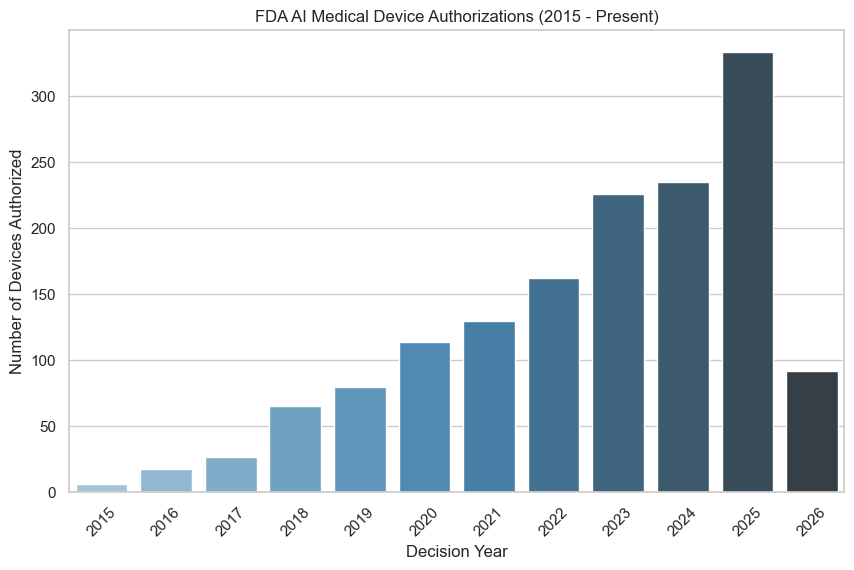

In [13]:
# Group by decision year and count authorizations (filtering for modern AI era > 2015)
yearly_auths = devices_clean[devices_clean['decision_year'] >= 2015]['decision_year'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
sns.barplot(x=yearly_auths.index, y=yearly_auths.values, palette="Blues_d")
plt.title("FDA AI Medical Device Authorizations (2015 - Present)")
plt.xlabel("Decision Year")
plt.ylabel("Number of Devices Authorized")
plt.xticks(rotation=45)
plt.show()

- **Observation:** Annual authorizations increased sharply from 65 in 2018 to 333 in 2025. The dataset contains 92 records for 2026 and ends on March 30, so 2026 is only a partial year. These counts show strong growth, but do not establish exponential growth or explain its causes.

#### Which specialties dominate the AI device landscape?

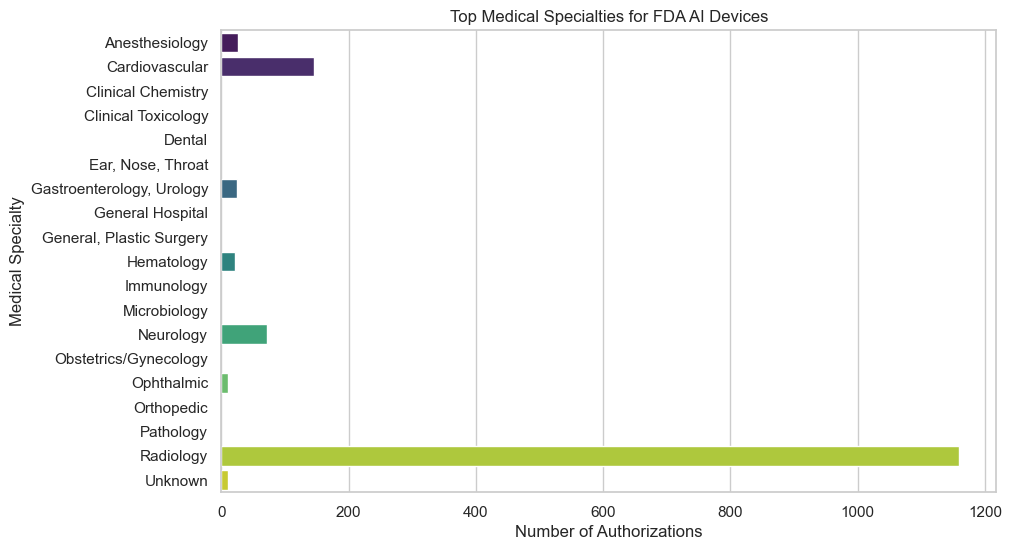

In [14]:
top_specialties = devices_clean['medical_specialty_description'].value_counts().head(8)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_specialties.values, y=top_specialties.index, palette="viridis")
plt.title("Top Medical Specialties for FDA AI Devices")
plt.xlabel("Number of Authorizations")
plt.ylabel("Medical Specialty")
plt.show()

- **Observation:** Radiology accounts for 1,160 of 1,524 authorizations (76.1%), far more than Cardiovascular (146) or Neurology (71). This shows a strong specialty concentration in the dataset; the counts do not establish why it occurs or measure model efficacy.

#### How do observed receipt-to-decision spans differ across pathways?

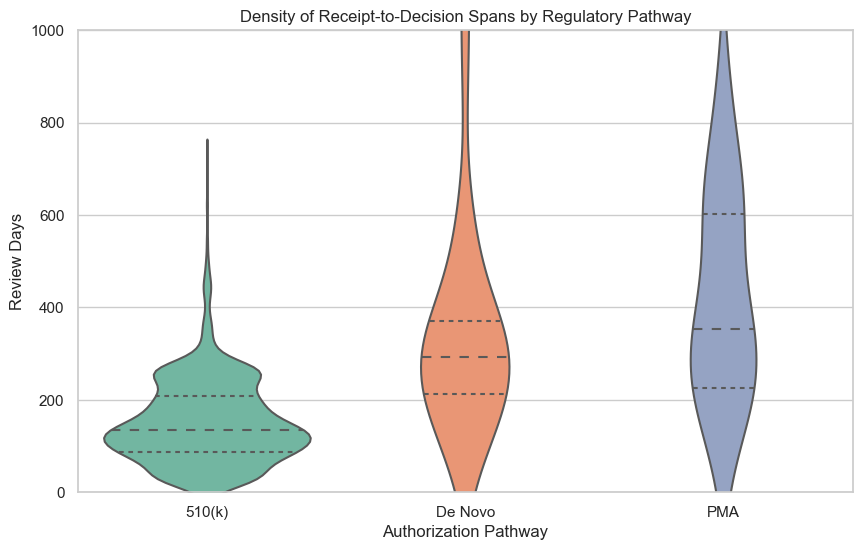

In [15]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=devices_clean, 
    x='authorization_pathway', 
    y='review_days', 
    palette="Set2",
    inner="quartile"
)
plt.title("Density of Receipt-to-Decision Spans by Regulatory Pathway")
plt.xlabel("Authorization Pathway")
plt.ylabel("Review Days")
plt.ylim(0, 1000) # Cap outliers for better visual scaling
plt.show()

- **Observation:** The 510(k) review-time median is 135 days (mean 152), compared with 293 days (mean 347) for De Novo and 353 days (mean 419) for PMA. De Novo and PMA also have wider ranges in this dataset. These descriptive spans show longer review times for those pathways here, but do not by themselves establish why.

#### What recall root-cause categories occur most often in exact-linked records?

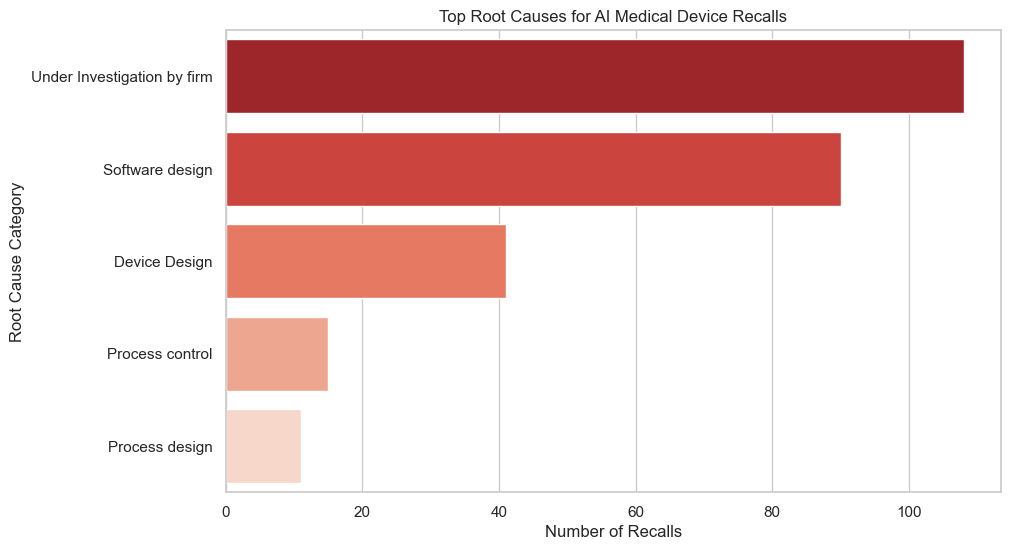

In [16]:
top_causes = recalls_clean['root_cause_description'].value_counts().head(5)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_causes.values, y=top_causes.index, palette="Reds_r")
plt.title("Top Root Causes for AI Medical Device Recalls")
plt.xlabel("Number of Recalls")
plt.ylabel("Root Cause Category")
plt.show()

- **Observation:** The plotted counts include unresolved cases: "Under Investigation by firm" is the most frequent category (108 records), followed by "Software design" (90) and "Device Design" (41). If unresolved cases are set aside, "Software design" is the most frequent single listed root-cause category. This is a count of linked recall records, not a measure of device-level risk.

#### Which pathways authorize AI-enabled devices and what is the overall review span?

In [17]:
# Display authorization pathways
print("Authorizations by Pathway:")
display(devices_clean['authorization_pathway'].value_counts().to_frame())

# Overall receipt-to-decision span
print("\nOverall Receipt-to-Decision Span (Days):")
display(devices_clean['review_days'].describe().to_frame())

Authorizations by Pathway:


,count
authorization_pathway,
510(k),1466
De Novo,39
PMA,19



Overall Receipt-to-Decision Span (Days):


,review_days
count,1524.000000
mean,160.578084
std,108.300377
min,7.000000
25%,89.000000
50%,138.000000
75%,217.000000
max,1136.000000


- **Observation:** 510(k) accounts for 1,466 of 1,524 authorizations (96.2%). Across all pathways, the mean receipt-to-decision span is 160.6 days and the median is 138 days. In this dataset, 510(k) has the shortest pathway-specific median (135 days), versus 293 for De Novo and 353 for PMA; this describes the observed records rather than proving a general regulatory speed advantage.

#### How concentrated is the AI-device landscape in radiology, and is that changing?

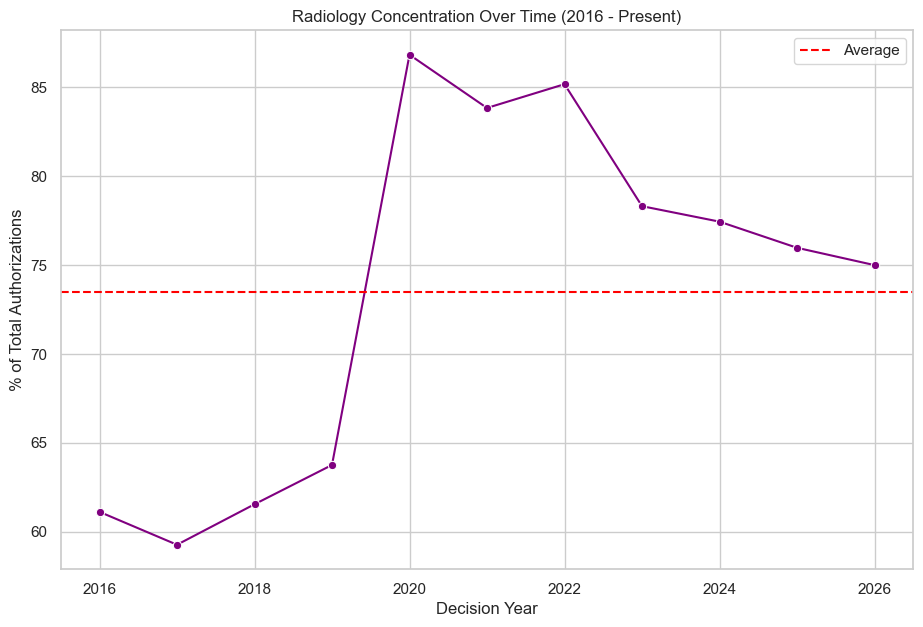

In [18]:
# Calculate the percentage of authorizations that are Radiology-focused per year (2016-2026)
yearly_totals = devices_clean.groupby('decision_year').size()
radiology_totals = devices_clean[devices_clean['medical_specialty_description'] == 'Radiology'].groupby('decision_year').size()

rad_concentration = pd.DataFrame({'Total': yearly_totals, 'Radiology': radiology_totals}).fillna(0).loc[2016:]
rad_concentration['Radiology_Percentage'] = (rad_concentration['Radiology'] / rad_concentration['Total']) * 100

plt.figure()
sns.lineplot(data=rad_concentration, x=rad_concentration.index, y='Radiology_Percentage', marker='o', color='purple')
plt.title("Radiology Concentration Over Time (2016 - Present)")
plt.xlabel("Decision Year")
plt.ylabel("% of Total Authorizations")
plt.axhline(rad_concentration['Radiology_Percentage'].mean(), color='red', linestyle='--', label='Average')
plt.legend()
plt.show()

- **Observation:** Radiology's share of annual authorizations peaked at 86.8% in 2020 and was 75.0% in 2026. The 2026 data end on March 30, so that year's share is preliminary. The declining share suggests authorizations are becoming less concentrated in Radiology, but does not on its own show which specialties are driving the change.

#### Which product classifications had the most authorizations from 2023 onward?

In [19]:
# Filter for authorizations after 2022
recent_devices = devices_clean[devices_clean['decision_year'] > 2022]
top_recent_codes = recent_devices['primary_product_code'].value_counts().head(5).to_frame().reset_index()

# Merge with codes_clean to get the classification name
top_recent_details = top_recent_codes.merge(
    codes_clean[['primary_product_code', 'classification_name']], 
    on='primary_product_code', 
    how='left'
)
display(top_recent_details)

,primary_product_code,count,classification_name
0,QIH,217,Automated Radiological Image Processing Software
1,IYN,77,"System, Imaging, Pulsed Doppler, Ultrasonic"
2,LNH,60,"System, Nuclear Magnetic Resonance Imaging"
3,JAK,52,"System, X-Ray, Tomography, Computed"
4,LLZ,44,"System, Image Processing, Radiological"


- **Observation:** Among authorizations from 2023 onward, QIH had the highest count (217), followed by IYN (77), LNH (60), JAK (52), and LLZ (44). QIH is classified as Automated Radiological Image Processing Software. This ranks counts in the selected period; it does not measure growth relative to an earlier period or explain the reason for the ranking.

#### Which authorization numbers appear in FDA recall records and what are the specific reasons?

In [20]:
# Top 5 recalled submission numbers
top_recalled = recalls_clean['submission_number'].value_counts().head(5)
print("Top 5 Authorization Numbers in Recall Records:")
display(top_recalled.to_frame())

# Sample recall reasons for the top root cause (Software design)
software_recalls = recalls_clean[recalls_clean['root_cause_description'] == 'Software design']
print("\nSample Recall Reasons for 'Software design':")
for reason in software_recalls['reason_for_recall'].head(3):
    print(f"- {reason[:120]}...")

Top 5 Authorization Numbers in Recall Records:


,count
submission_number,
K190387,32
K213583,31
K212441,16
K200569,14
K120771,11



Sample Recall Reasons for 'Software design':
- GE HealthCare has become aware of a potential security vulnerability impacting AW Server deployed via Edison Health Link...
- There is a potential cybersecurity vulnerability affecting certain versions of Centricity Universal Viewer. User login c...
- Ortho images acquired with preset automatic horizontal flip are not flipped and when acquiring single images, there is t...


- **Observation:** The submission numbers with the most linked recall records are K190387 (32), K213583 (31), K212441 (16), K200569 (14), and K120771 (11). The sample reasons for records categorized as "Software design" include potential cybersecurity vulnerabilities in GE HealthCare viewer systems and an image-flipping issue. These examples illustrate reported software-related problems, but this output does not show the root-cause breakdown for the five most-recalled submissions or establish that software design is their primary issue.

#### How sensitive are recall comparisons to authorization year and time at risk?

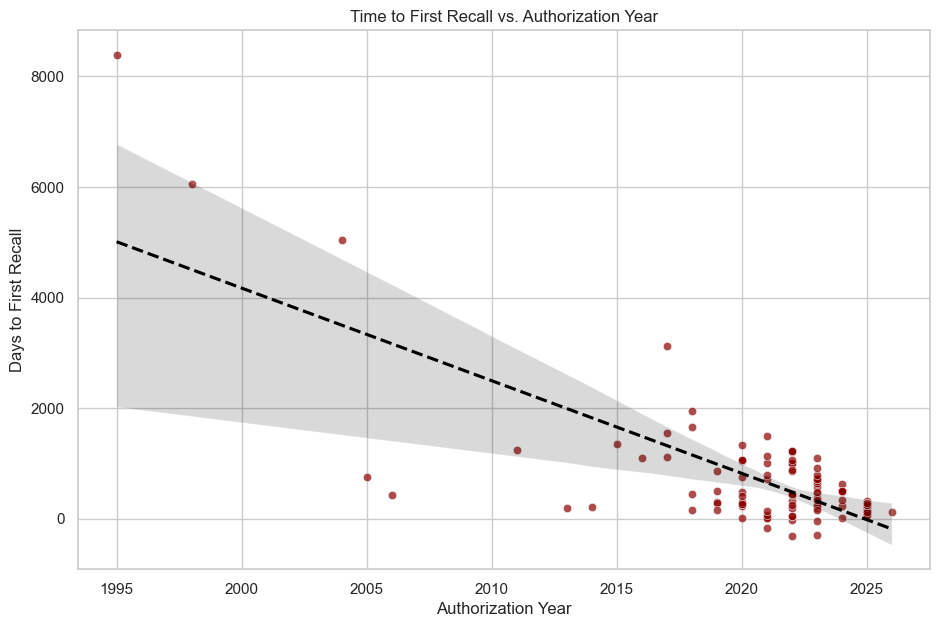

In [21]:
# Join devices with their recall time data
devices_with_recalls = devices_clean[devices_clean['has_linked_recall'] == 1]

plt.figure()
sns.scatterplot(data=devices_with_recalls, x='decision_year', y='days_to_first_recall', alpha=0.7, color='darkred')
sns.regplot(data=devices_with_recalls, x='decision_year', y='days_to_first_recall', scatter=False, color='black', line_kws={"linestyle":"--"})
plt.title("Time to First Recall vs. Authorization Year")
plt.xlabel("Authorization Year")
plt.ylabel("Days to First Recall")
plt.show()

- **Observation:** Among devices with a linked recall, median days to first recall were 534 for 2023 authorizations (n=20), 503 for 2024 (n=9), 176.5 for 2025 (n=10), and 122 for 2026 (n=1). The recent cohorts have less observed follow-up, and the very small 2026 sample is especially uncertain. The scatterplot does not estimate recall risk or establish that newer devices are safer; fair comparisons would need to account for time at risk.
- **What information is lost when recalls lack a submission number?** All 313 recall-link records in this dataset match a device submission number (102 distinct submissions; no unmatched submission numbers). Without that key, this exact join to authorization details would be unavailable and attribution to product code, risk classification, and review timeline would be less certain; other identifiers might still support matching.

<a id="conclusions"></a>

### Conclusions

- **Data Quality:** The three tables have no full-row duplicates, and the notebook converts selected date and categorical fields for analysis. This is not a complete validation of source accuracy or missingness; some fields are null in the source data.
- **Authorization trend:** Annual counts rise from 65 in 2018 to 333 in 2025. The dataset ends on March 30, 2026 (92 records), so 2026 is partial. These counts support strong growth, not a demonstrated exponential trend or an explanation for it.
- **Specialty distribution:** Radiology represents 1,160 of 1,524 authorizations (76.1%); its annual share peaked at 86.8% in 2020 and was 75.0% in the partial 2026 data. The dataset shows concentration, not its cause or clinical efficacy.
- **Pathways and review span:** 510(k) accounts for 1,466 authorizations (96.2%). Its median observed review span is 135 days, versus 293 for De Novo and 353 for PMA. These are descriptive statistics for this dataset, not proof of a general pathway effect.
- **Recall records:** "Under Investigation by firm" is the largest single root-cause category (108 of 313 linked records), followed by "Software design" (90) and "Device Design" (41). Software design is the most frequent single category among records not marked as under investigation, but these counts are not device-level risk estimates.
- **Interpretation limits:** Recall records are linked to 102 distinct authorization submissions, and recent authorization cohorts have had less time for recalls to be observed. Neither the recall counts nor the plotted time-to-first-recall data establish comparative safety or causation; comparisons should account for follow-up time.